# 使用 Pytorch训练一个可学习的 Attention 网络

使用 PyTorch 训练一个可学习的 Attention 网络，让它根据指定位置，从一串token中找出对应token。


阶段一：独立设计（20～30 分钟）
不让我提供实现步骤，先自己思考需要什么数据、怎样表示查询位置、模型应该输入和输出什么，以及需要哪些模块。可以查 NumPy、PyTorch 的 API。

阶段二：独立实现（30～45 分钟）
尝试构造数据，并写出最简单的 Attention 前向传播。遇到困难先自己检查形状、查文档，不必要求一次完成训练。

阶段三：我来检查和提示
你把自己的设计、代码或者卡住的地方发给我。我优先指出问题和给出最小提示，而不是直接接管整个实现。

## Attention计算拆解：

整体数据流：
1. 输入数据shape=(n, 6, 8)，假设每个token用8维向量表示
2. 输入数据的每个token注入位置编码
3. 设计QKV的size。W.shape=(8, 12), Q.shape=K.shape=V.shape=(6, 12), A.shape=(6, 6), H.shape=(6, 12)，最终输出的是6个token的向量信息
4. 取`H[:-1:]`，送入(12, 5)的全连接层（假设词表包含5个汉字），再softmax，得到结果

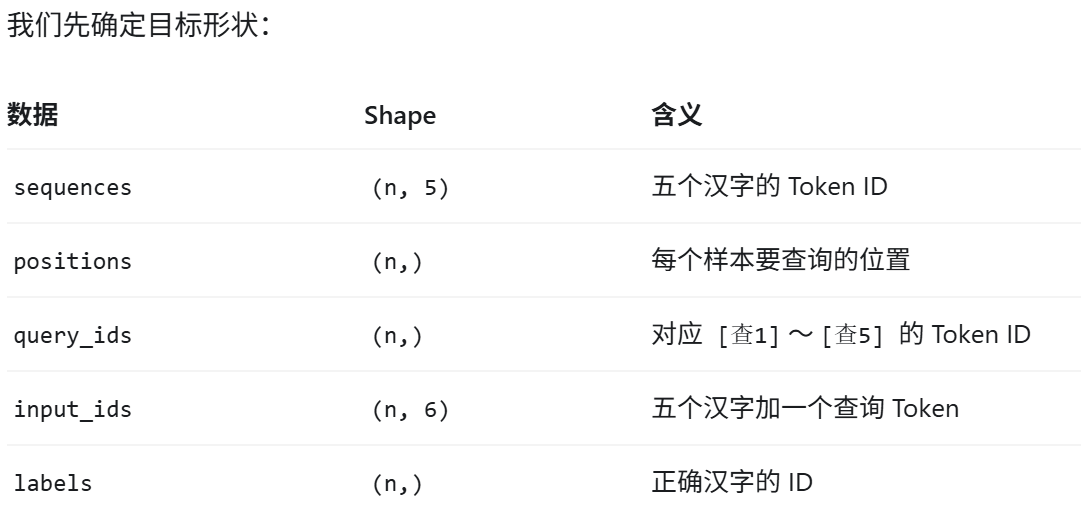

### 数据准备：

**注：**本实验采用人工构造的小词表，将“第一个”至“第五个”分别作为独立的查询 Token，以简化自然语言理解问题，重点研究 Attention 如何通过训练学习位置匹配关系。

In [1]:
# 定义词表
vocab = {
    "花" : 0,
    "鸟" : 1,
    "虫" : 2,
    "鱼" : 3,
    "猫" : 4,
    "第一个" : 5,
    "第二个" : 6,
    "第三个" : 7,
    "第四个" : 8,
    "第五个" : 9
}

import numpy as np
import torch

In [2]:
# 生成训练数据
rng = np.random.default_rng(42)
n = 1000
sequences = rng.integers(0, 5, size=(n, 5))
"训练词表", sequences[:5], sequences.shape

('训练词表',
 array([[0, 3, 3, 2, 2],
        [4, 0, 3, 1, 0],
        [2, 4, 3, 3, 3],
        [3, 2, 0, 4, 2],
        [2, 1, 0, 4, 3]]),
 (1000, 5))

In [3]:
positions = rng.integers(1, 6, size=(n))
"要查询的位置", positions[:5], positions.shape

('要查询的位置', array([1, 1, 4, 4, 4]), (1000,))

In [4]:
input_ids = np.concatenate([sequences, positions[:, None] + 4], axis=1)
"输入", input_ids[:5], input_ids.shape

('输入',
 array([[0, 3, 3, 2, 2, 5],
        [4, 0, 3, 1, 0, 5],
        [2, 4, 3, 3, 3, 8],
        [3, 2, 0, 4, 2, 8],
        [2, 1, 0, 4, 3, 8]]),
 (1000, 6))

In [5]:
labels = sequences[np.arange(n), positions - 1]
labels[:5], labels.shape

(array([0, 4, 3, 4, 4]), (1000,))

### 数据集划分

In [6]:
from sklearn.model_selection import train_test_split

In [7]:
inputs_train, inputs_tmp, labels_train, labels_tmp = train_test_split(
    input_ids,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels,
)
inputs_val, inputs_test, labels_val, labels_test = train_test_split(
    inputs_tmp,
    labels_tmp,
    test_size=0.5,
    random_state=42,
    stratify=labels_tmp,
)
inputs_train.shape, inputs_val.shape, inputs_test.shape, labels_train.shape

((800, 6), (100, 6), (100, 6), (800,))

### Embedding

In [8]:
torch.manual_seed(42)
inputs_train_tensor = torch.tensor(inputs_train, dtype=torch.long)
embedding = torch.nn.Embedding(10, 8)

In [9]:
inputs_embedded = embedding(inputs_train_tensor)
inputs_train[0], inputs_embedded[0], inputs_embedded.shape

(array([1, 1, 3, 0, 1, 6]),
 tensor([[-0.7521,  1.6487, -0.3925, -1.4036, -0.7279, -0.5594, -0.7688,  0.7624],
         [-0.7521,  1.6487, -0.3925, -1.4036, -0.7279, -0.5594, -0.7688,  0.7624],
         [ 1.2791,  1.2964,  0.6105,  1.3347, -0.2316,  0.0418, -0.2516,  0.8599],
         [ 1.9269,  1.4873,  0.9007, -2.1055,  0.6784, -1.2345, -0.0431, -1.6047],
         [-0.7521,  1.6487, -0.3925, -1.4036, -0.7279, -0.5594, -0.7688,  0.7624],
         [-0.9138, -0.6581,  0.0780,  0.5258, -0.4880,  1.1914, -0.8140, -0.7360]],
        grad_fn=<SelectBackward0>),
 torch.Size([800, 6, 8]))

### 位置嵌入

| 位置嵌入方法 | 是否有可训练参数 | 是否随训练更新 |
| ---- | ---- | ---- |
| 固定正余弦位置编码 | 否 | 否 |
| 可学习位置嵌入 | 是 | 是 |

固定正余弦位置编码通过确定的数学公式计算：
$$
PE(pos,2i)=\sin\left(\frac{pos}{10000^{2i/d}}\right)
$$

$$
PE(pos,2i+1)=\cos\left(\frac{pos}{10000^{2i/d}}\right)
$$

它不需要学习，训练前后数值不变。
可学习位置嵌入则与 Token Embedding 类似，可以使用另一个 nn.Embedding 层，为不同位置维护可训练向量。
例如：
```
token_embedding = nn.Embedding(10, 8)
position_embedding = nn.Embedding(6, 8)
```


两种向量相加：
$$
X=E_{\text{token}}+E_{\text{position}}
$$

这样，模型就能同时学习 Token 的表示和位置的表示。

本次实践采用可学习位置嵌入，能同时观察：
- Token Embedding 如何学习汉字和查询符号的表示；
- Position Embedding 如何学习不同位置的表示；
- QKV 投影如何学习查询位置与实际位置之间的匹配关系。

In [10]:
position_embedding = torch.nn.Embedding(6, 8) # 从6个位置分别映射为一个8维向量

In [11]:
position_ids = torch.arange(6)
position_embedded = position_embedding(position_ids)
position_embedded.shape
# 获得6个位置的position_Embedding向量

torch.Size([6, 8])

In [12]:
# 利用广播机制，直接嵌入到每个seq的每个token向量中
inputs_pos_embedded = inputs_embedded + position_embedded
inputs_pos_embedded.shape

torch.Size([800, 6, 8])

至此，输入数据已经准备完毕并且进行了位置嵌入。

### 实现Q、K、V

$W_Q, W_K, W_V$对每一个token进行投影，转化为$Q、K、V$。

设一个token的$Q、K、V$的维度为12，那么投影矩阵的维度应该是$8\times 12$

In [13]:
W_query = torch.nn.Linear(8, 12, bias=False)
W_key = torch.nn.Linear(8, 12, bias=False)
W_value = torch.nn.Linear(8, 12, bias=False)
# 给投影函数不加偏置，以达到Q=WX的效果

In [14]:
query = W_query(inputs_pos_embedded)
key = W_key(inputs_pos_embedded)
value = W_value(inputs_pos_embedded)
query.shape, key.shape, value.shape

(torch.Size([800, 6, 12]), torch.Size([800, 6, 12]), torch.Size([800, 6, 12]))

### 计算A、H

In [15]:
key_T = key.transpose(1, 2)
key.shape, key_T.shape

(torch.Size([800, 6, 12]), torch.Size([800, 12, 6]))

In [16]:
# 用缩放点积模型计算注意力权重
QKT = torch.bmm(query, key_T)
QKT.shape

torch.Size([800, 6, 6])

In [17]:
scaled_QKT = QKT/np.sqrt(key.shape[-1])
np.sqrt(key.shape[-1]), QKT[0], scaled_QKT[0]

(np.float64(3.4641016151377544),
 tensor([[-1.7290, -1.7936, -0.5159,  0.9871, -5.0706,  0.5428],
         [-0.3045, -0.0455,  1.1961, -4.5143, -1.4654,  1.5487],
         [ 1.4076,  1.9944, -0.7271, -1.4469,  1.2087, -0.4798],
         [-1.2378,  0.9427, -2.3490,  2.3946, -1.7647, -2.4083],
         [-0.3697, -1.1252, -0.0433, -0.0748, -3.4250,  0.9716],
         [ 0.7852, -0.0334,  0.5555,  0.4364,  1.7705,  0.4121]],
        grad_fn=<SelectBackward0>),
 tensor([[-0.4991, -0.5178, -0.1489,  0.2849, -1.4637,  0.1567],
         [-0.0879, -0.0131,  0.3453, -1.3032, -0.4230,  0.4471],
         [ 0.4063,  0.5757, -0.2099, -0.4177,  0.3489, -0.1385],
         [-0.3573,  0.2721, -0.6781,  0.6913, -0.5094, -0.6952],
         [-0.1067, -0.3248, -0.0125, -0.0216, -0.9887,  0.2805],
         [ 0.2267, -0.0097,  0.1604,  0.1260,  0.5111,  0.1190]],
        grad_fn=<SelectBackward0>))

In [18]:
attention = torch.nn.functional.softmax(scaled_QKT, dim=-1)
attention.shape

torch.Size([800, 6, 6])

In [19]:
hidden = torch.bmm(attention, value)
hidden.shape, hidden[0]

(torch.Size([800, 6, 12]),
 tensor([[-0.1445, -0.0709,  0.2008, -0.0830,  0.0239, -0.1829,  0.0030,  0.3304,
           0.4059,  0.2906,  0.1794,  0.3625],
         [-0.1429, -0.0122,  0.0517,  0.1378,  0.0938, -0.1329,  0.1289,  0.1255,
           0.2428, -0.0513,  0.1095,  0.2395],
         [-0.2695, -0.0736,  0.2063,  0.0744,  0.3463, -0.2057, -0.1158,  0.3543,
           0.5099,  0.1449,  0.3183,  0.1646],
         [-0.2147, -0.0792,  0.3449, -0.1560,  0.2124, -0.3139, -0.1985,  0.5776,
           0.6287,  0.5523,  0.3959,  0.2628],
         [-0.1785, -0.0709,  0.1535, -0.0056,  0.0782, -0.1464,  0.0108,  0.2594,
           0.3711,  0.1638,  0.1488,  0.3265],
         [-0.1955, -0.0992,  0.2136,  0.0361,  0.2387, -0.1882,  0.0046,  0.3746,
           0.5034,  0.0977,  0.3057,  0.2966]], grad_fn=<SelectBackward0>))

### 提取输出，计算结果

因为只需要每个seq的最后一个token，即查询token的Hidden，因此将其提取出来做一个(12, 5)的线性变换，得到logits
logits只有词表中的前5个字的得分。

In [20]:
hidden_q = hidden[:, -1, :]
hidden_q.shape

torch.Size([800, 12])

In [21]:
fc = torch.nn.Linear(12, 5)
logits = fc(hidden_q)
logits.shape, logits

(torch.Size([800, 5]),
 tensor([[-0.0785, -0.2070,  0.0902, -0.0437,  0.2701],
         [-0.1446, -0.0994, -0.2116,  0.0147,  0.2507],
         [ 0.1073, -0.2650,  0.0737, -0.0993,  0.3075],
         ...,
         [-0.1390, -0.2331,  0.0086,  0.0180,  0.3011],
         [ 0.0066, -0.1637, -0.0512, -0.0439,  0.2649],
         [-0.0536, -0.1588,  0.0841,  0.0812,  0.2939]],
        grad_fn=<AddmmBackward0>))

### 计算损失

In [22]:
loss_fc = torch.nn.CrossEntropyLoss()
loss = loss_fc(logits, torch.tensor(labels_train))
loss

tensor(1.6069, grad_fn=<NllLossBackward0>)

In [23]:
loss.backward()

In [24]:
print(W_query.weight.grad is not None)
print(embedding.weight.grad is not None)
print(position_embedding.weight.grad is not None)

True
True
True


此时梯度已经反向传播回W中

## 封装模型和训练

### 训练

In [25]:
import numpy as np
import torch
import torch.nn as nn

class SelfAttentionModel(nn.Module):
    def __init__(self):
        super().__init__()

        # 1.Embedding 
        self.token_embedding = nn.Embedding(10, 8)
        self.position_embedding = nn.Embedding(6, 8)

        # 2.QKV投影
        self.W_query = nn.Linear(8, 12, bias=False)
        self.W_key = nn.Linear(8, 12, bias=False)
        self.W_value = nn.Linear(8, 12, bias=False)

        # 3.分类层（全连接层）
        self.fc = nn.Linear(12, 5)

    def forward(self, input_ids: torch.Tensor):
        # Token Embedding + Position Embedding
        inputs_embedded = self.token_embedding(input_ids)
        position_embedded = self.position_embedding(torch.arange(6))
        inputs_pos_embedded = inputs_embedded + position_embedded
        
        # Q、K、V
        query = self.W_query(inputs_pos_embedded)
        key = self.W_key(inputs_pos_embedded)
        value = self.W_value(inputs_pos_embedded)
        
        # 缩放点积与 Softmax
        key_T = key.transpose(1, 2)
        qkt = torch.bmm(query, key_T)
        scaled_qkt = qkt / np.sqrt(key.shape[-1])
        attention = nn.functional.softmax(scaled_qkt, dim=-1)
        
        # Attention × V
        hidden = torch.bmm(attention, value)
        # 提取最后一个 Token
        hidden_q = hidden[:, -1, :]
        # 分类层
        logits = self.fc(hidden_q)
        
        # 最后 return scores
        return logits, attention

In [26]:
model = SelfAttentionModel()
logits, _ = model.forward(inputs_train_tensor)
logits.shape

torch.Size([800, 5])

In [27]:
def train_step(epochs, alpha=0.01):
    model = SelfAttentionModel()
    loss_fn = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=alpha)
    labels_train_tensor = torch.tensor(labels_train)

    for epoch in range(epochs):
        optimizer.zero_grad()
        logits, attention = model(inputs_train_tensor)
        loss = loss_fn(logits, labels_train_tensor)
        loss.backward()
        optimizer.step()

        if epoch % 100 == 0:
            print(loss)

    return model, attention

In [28]:
model, attention = train_step(201)

tensor(1.6390, grad_fn=<NllLossBackward0>)
tensor(0.0003, grad_fn=<NllLossBackward0>)
tensor(0.0001, grad_fn=<NllLossBackward0>)


### 验证集测试

In [29]:
model.eval()
with torch.no_grad():
    logits_val, _ = model(torch.tensor(inputs_val))
    loss = torch.nn.CrossEntropyLoss()(logits_val, torch.tensor(labels_val))
    print(loss)

tensor(0.0001)


### 测试集测试

In [30]:
with torch.no_grad():
    logits_test, _ = model(torch.tensor(inputs_test))
    loss = torch.nn.CrossEntropyLoss()(logits_test, torch.tensor(labels_test))
    print(loss)

tensor(0.0001)


In [31]:
test_pred = torch.argmax(logits_test, dim=-1)
acc = (test_pred == labels_test).float().mean()
acc

tensor(1.)

正确率为$100\%$

### 查看attention

查看是否是对应token的注意力权重最高

In [32]:
for i in range(0, inputs_train.shape[0], 150):
    print(inputs_train[i][-1] - 4, attention[i][-1][:5])

2 tensor([1.7714e-03, 9.9396e-01, 5.1851e-05, 1.3142e-05, 4.1861e-03],
       grad_fn=<SliceBackward0>)
5 tensor([1.2075e-05, 3.1530e-02, 1.8955e-04, 2.9932e-04, 9.5673e-01],
       grad_fn=<SliceBackward0>)
5 tensor([1.9777e-05, 2.0026e-02, 2.6879e-04, 1.9011e-04, 9.6929e-01],
       grad_fn=<SliceBackward0>)
1 tensor([9.9462e-01, 3.5350e-04, 3.8477e-03, 9.9427e-05, 2.0855e-08],
       grad_fn=<SliceBackward0>)
2 tensor([0.0086, 0.9810, 0.0041, 0.0019, 0.0041], grad_fn=<SliceBackward0>)
3 tensor([5.9423e-03, 2.3927e-04, 9.6614e-01, 1.6426e-06, 6.5468e-05],
       grad_fn=<SliceBackward0>)


符合预期。